# Mask R-CNN vs SAM2 (zero-shot AMG) on FoodSeg103 test

All models are scored with `foodseg_common` against the same class-agnostic ground truth
(one instance per food-class region, area >= 100 px), on the same test images.

Prediction caches (any that are missing are skipped):
- `outputs/maskrcnn_test.pkl`: `MaskRCNN.ipynb` section 7 (fine-tuned)
- `outputs/maskrcnn_custom_test.pkl`: `MaskRCNN_Customized.ipynb` Step 7b (fine-tuned, customized)
- `outputs/maskrcnn_zeroshot_test.pkl`: `MaskRCNN.ipynb` section 10 (COCO-pretrained, zero-shot)
- `outputs/sam2_amg_test.pkl`: `SAM2.ipynb` section 6 (zero-shot, AMG thresholds tuned on val)
- `outputs/sam2_standard_test.pkl`: `SAM2_Standard.ipynb` section 4 (zero-shot, default AMG settings, no tuning)
- `outputs/sam2_finetuned_test.pkl`: `SAM2_Standard.ipynb` section 8 (decoder fine-tuned on FoodSeg103, default AMG settings)

Each score threshold was chosen on the validation split (the standard and fine-tuned SAM2 runs keep every mask, threshold 0).

| Metric | Meaning |
|---|---|
| AP, AP50, AP75 | COCO mask AP (threshold-free ranking quality) |
| AR100 | COCO mask recall with up to 100 predictions |
| P/R/F1@50, @75 | one-to-one matching at the validation-chosen score threshold |
| gt_coverage_mean | mean best IoU any prediction reaches for each GT region (mask quality, no threshold) |
| fg_iou | union of predictions vs union of GT (food vs non-food segmentation) |

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

import foodseg_common as fc

CACHE_DIR = fc.OUT_ROOT
SPLIT = 'test'
MODELS = {
    'Mask R-CNN (customized)': CACHE_DIR / 'maskrcnn_custom_test.pkl',
    'Mask R-CNN (zero-shot)': CACHE_DIR / 'maskrcnn_zeroshot_test.pkl',
    'SAM2 AMG (standard)': CACHE_DIR / 'sam2_standard_test.pkl',
    'SAM2 AMG (fine-tuned)': CACHE_DIR / 'sam2_finetuned_test.pkl',
}

preds, meta = {}, {}
for name, p in MODELS.items():
    if not p.exists():
        print(f'{name}: {p.name} not found, skipped')
        continue
    preds[name], meta[name] = fc.load_preds(p)
    print(f'{name}: {len(preds[name])} images, score_thr={meta[name]["score_thr"]}')
assert len(preds) >= 2, 'Need at least two prediction caches to compare.'

# evaluate only images present in every cache
common = sorted(set.intersection(*(set(p) for p in preds.values())))
preds = {name: {sid: p[sid] for sid in common} for name, p in preds.items()}
print('Common test images:', len(common))

Mask R-CNN (customized): 1069 images, score_thr=0.85
Mask R-CNN (zero-shot): 1069 images, score_thr=0.35
SAM2 AMG (standard): 1069 images, score_thr=0.0
SAM2 AMG (fine-tuned): 1069 images, score_thr=0.0
Common test images: 1069


## 1 Results table

In [3]:
results = {}
caches = {}
for name, p in preds.items():
    results[name] = dict(fc.evaluate(p, SPLIT, score_thr=meta[name]['score_thr']),
                         sec_per_image=meta[name].get('sec_per_image', np.nan))
    caches[name] = fc.build_iou_cache(p, SPLIT)

table = pd.DataFrame(results)
table.to_csv(CACHE_DIR / 'comparison_test.csv')
(CACHE_DIR / 'comparison_test.json').write_text(json.dumps(
    dict(results=results, meta={k: {kk: str(vv) for kk, vv in m.items()} for k, m in meta.items()}), indent=2))
table.style.format('{:.4f}')

,Mask R-CNN (customized),Mask R-CNN (zero-shot),SAM2 AMG (standard),SAM2 AMG (fine-tuned)
n_images,1069.0000,1069.0000,1069.0000,1069.0000
score_thr,0.8500,0.3500,0.0000,0.0000
AP,0.3142,0.0749,0.0471,0.3651
AP50,0.5632,0.1546,0.0718,0.4396
AP75,0.2971,0.0632,0.0440,0.3766
AP_small,0.0097,0.0011,0.0018,0.0000
AP_medium,0.1655,0.0305,0.0188,0.2003
AP_large,0.3538,0.1133,0.0585,0.4112
AR1,0.1472,0.0998,0.0703,0.2039
AR10,0.4867,0.2403,0.1905,0.4601


## 2 Precision–recall (varying score threshold)

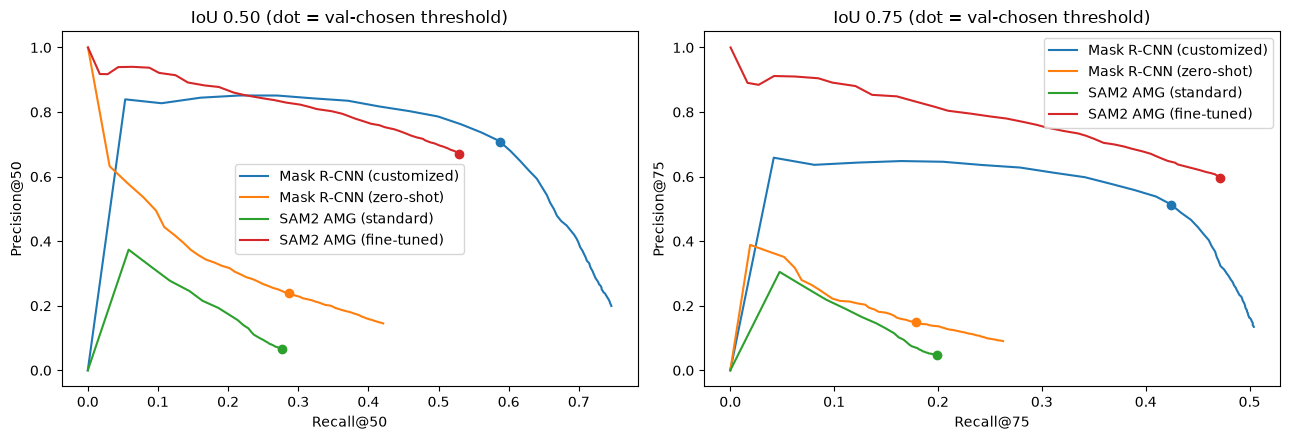

In [4]:
def score_grid(cache, n=60):
    """Score thresholds spanning each model's own score range (models score on different scales)."""
    s = np.concatenate([c['scores'] for c in cache])
    return np.unique(np.quantile(s, np.linspace(0, 1, n))) if s.size else np.array([0.0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, cache in caches.items():
    sw = pd.DataFrame(fc.threshold_sweep(cache, score_grid(cache)))
    chosen = fc.metrics(cache, meta[name]['score_thr'])
    for ax, n in zip(axes, (50, 75)):
        line, = ax.plot(sw[f'recall@{n}'], sw[f'precision@{n}'], label=name)
        ax.scatter(chosen[f'recall@{n}'], chosen[f'precision@{n}'], color=line.get_color(), zorder=3)
for ax, n in zip(axes, (50, 75)):
    ax.set_xlabel(f'Recall@{n}'); ax.set_ylabel(f'Precision@{n}')
    ax.set_title(f'IoU {n/100:.2f} (dot = val-chosen threshold)'); ax.legend()
plt.tight_layout(); plt.show()

## 3 Per-image F1@50 and coverage by GT region size

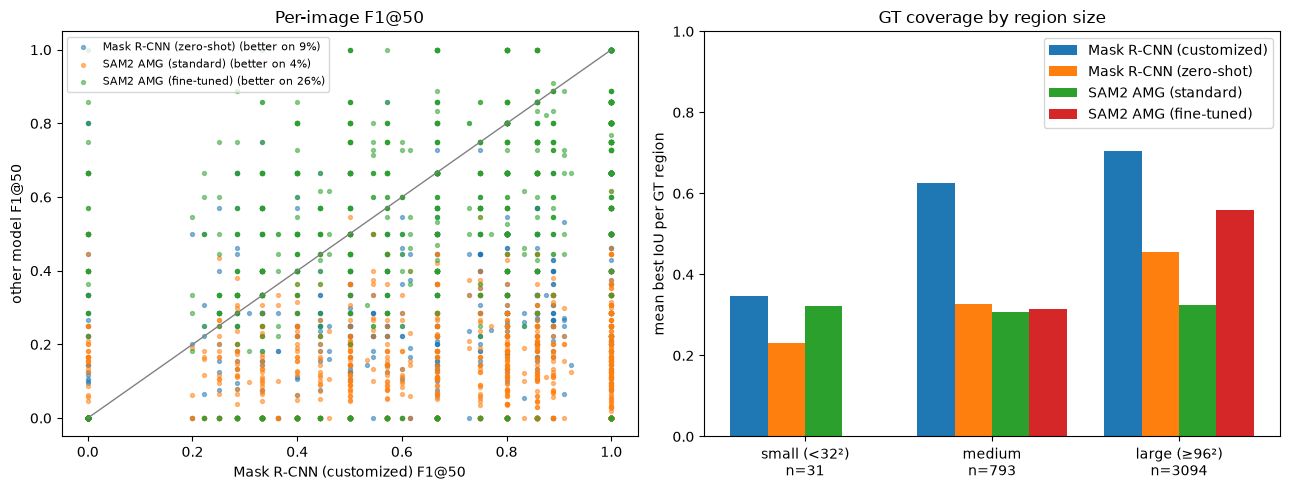

In [5]:
f1 = {name: fc.per_image_f1(c, meta[name]['score_thr']) for name, c in caches.items()}
ref, *others = list(f1)   # every other model is plotted against the first one
x = np.array([f1[ref][s] for s in common])

# GT region areas in the same order as fc.gt_coverage()
areas = np.concatenate([mask_utils.area(fc.gt_for(SPLIT, c['id'])[0]) for c in caches[ref] if c['n_gt']])
bins = {'small (<32²)': areas < 32**2,
        'medium': (areas >= 32**2) & (areas < 96**2),
        'large (≥96²)': areas >= 96**2}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in others:
    y = np.array([f1[name][s] for s in common])
    axes[0].scatter(x, y, s=8, alpha=0.5, label=f'{name} (better on {(y > x).mean():.0%})')
axes[0].plot([0, 1], [0, 1], color='grey', linewidth=1)
axes[0].set_xlabel(f'{ref} F1@50'); axes[0].set_ylabel('other model F1@50')
axes[0].set_title('Per-image F1@50'); axes[0].legend(fontsize=8)

width = 0.8 / len(caches)
for k, name in enumerate(caches):
    cov = fc.gt_coverage(caches[name])
    vals = [cov[m].mean() if m.any() else 0 for m in bins.values()]
    axes[1].bar(np.arange(len(bins)) + (k - (len(caches) - 1) / 2) * width, vals, width, label=name)
axes[1].set_xticks(np.arange(len(bins)), [f'{k}\nn={m.sum()}' for k, m in bins.items()])
axes[1].set_ylabel('mean best IoU per GT region'); axes[1].set_ylim(0, 1)
axes[1].set_title('GT coverage by region size'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4 Qualitative comparison

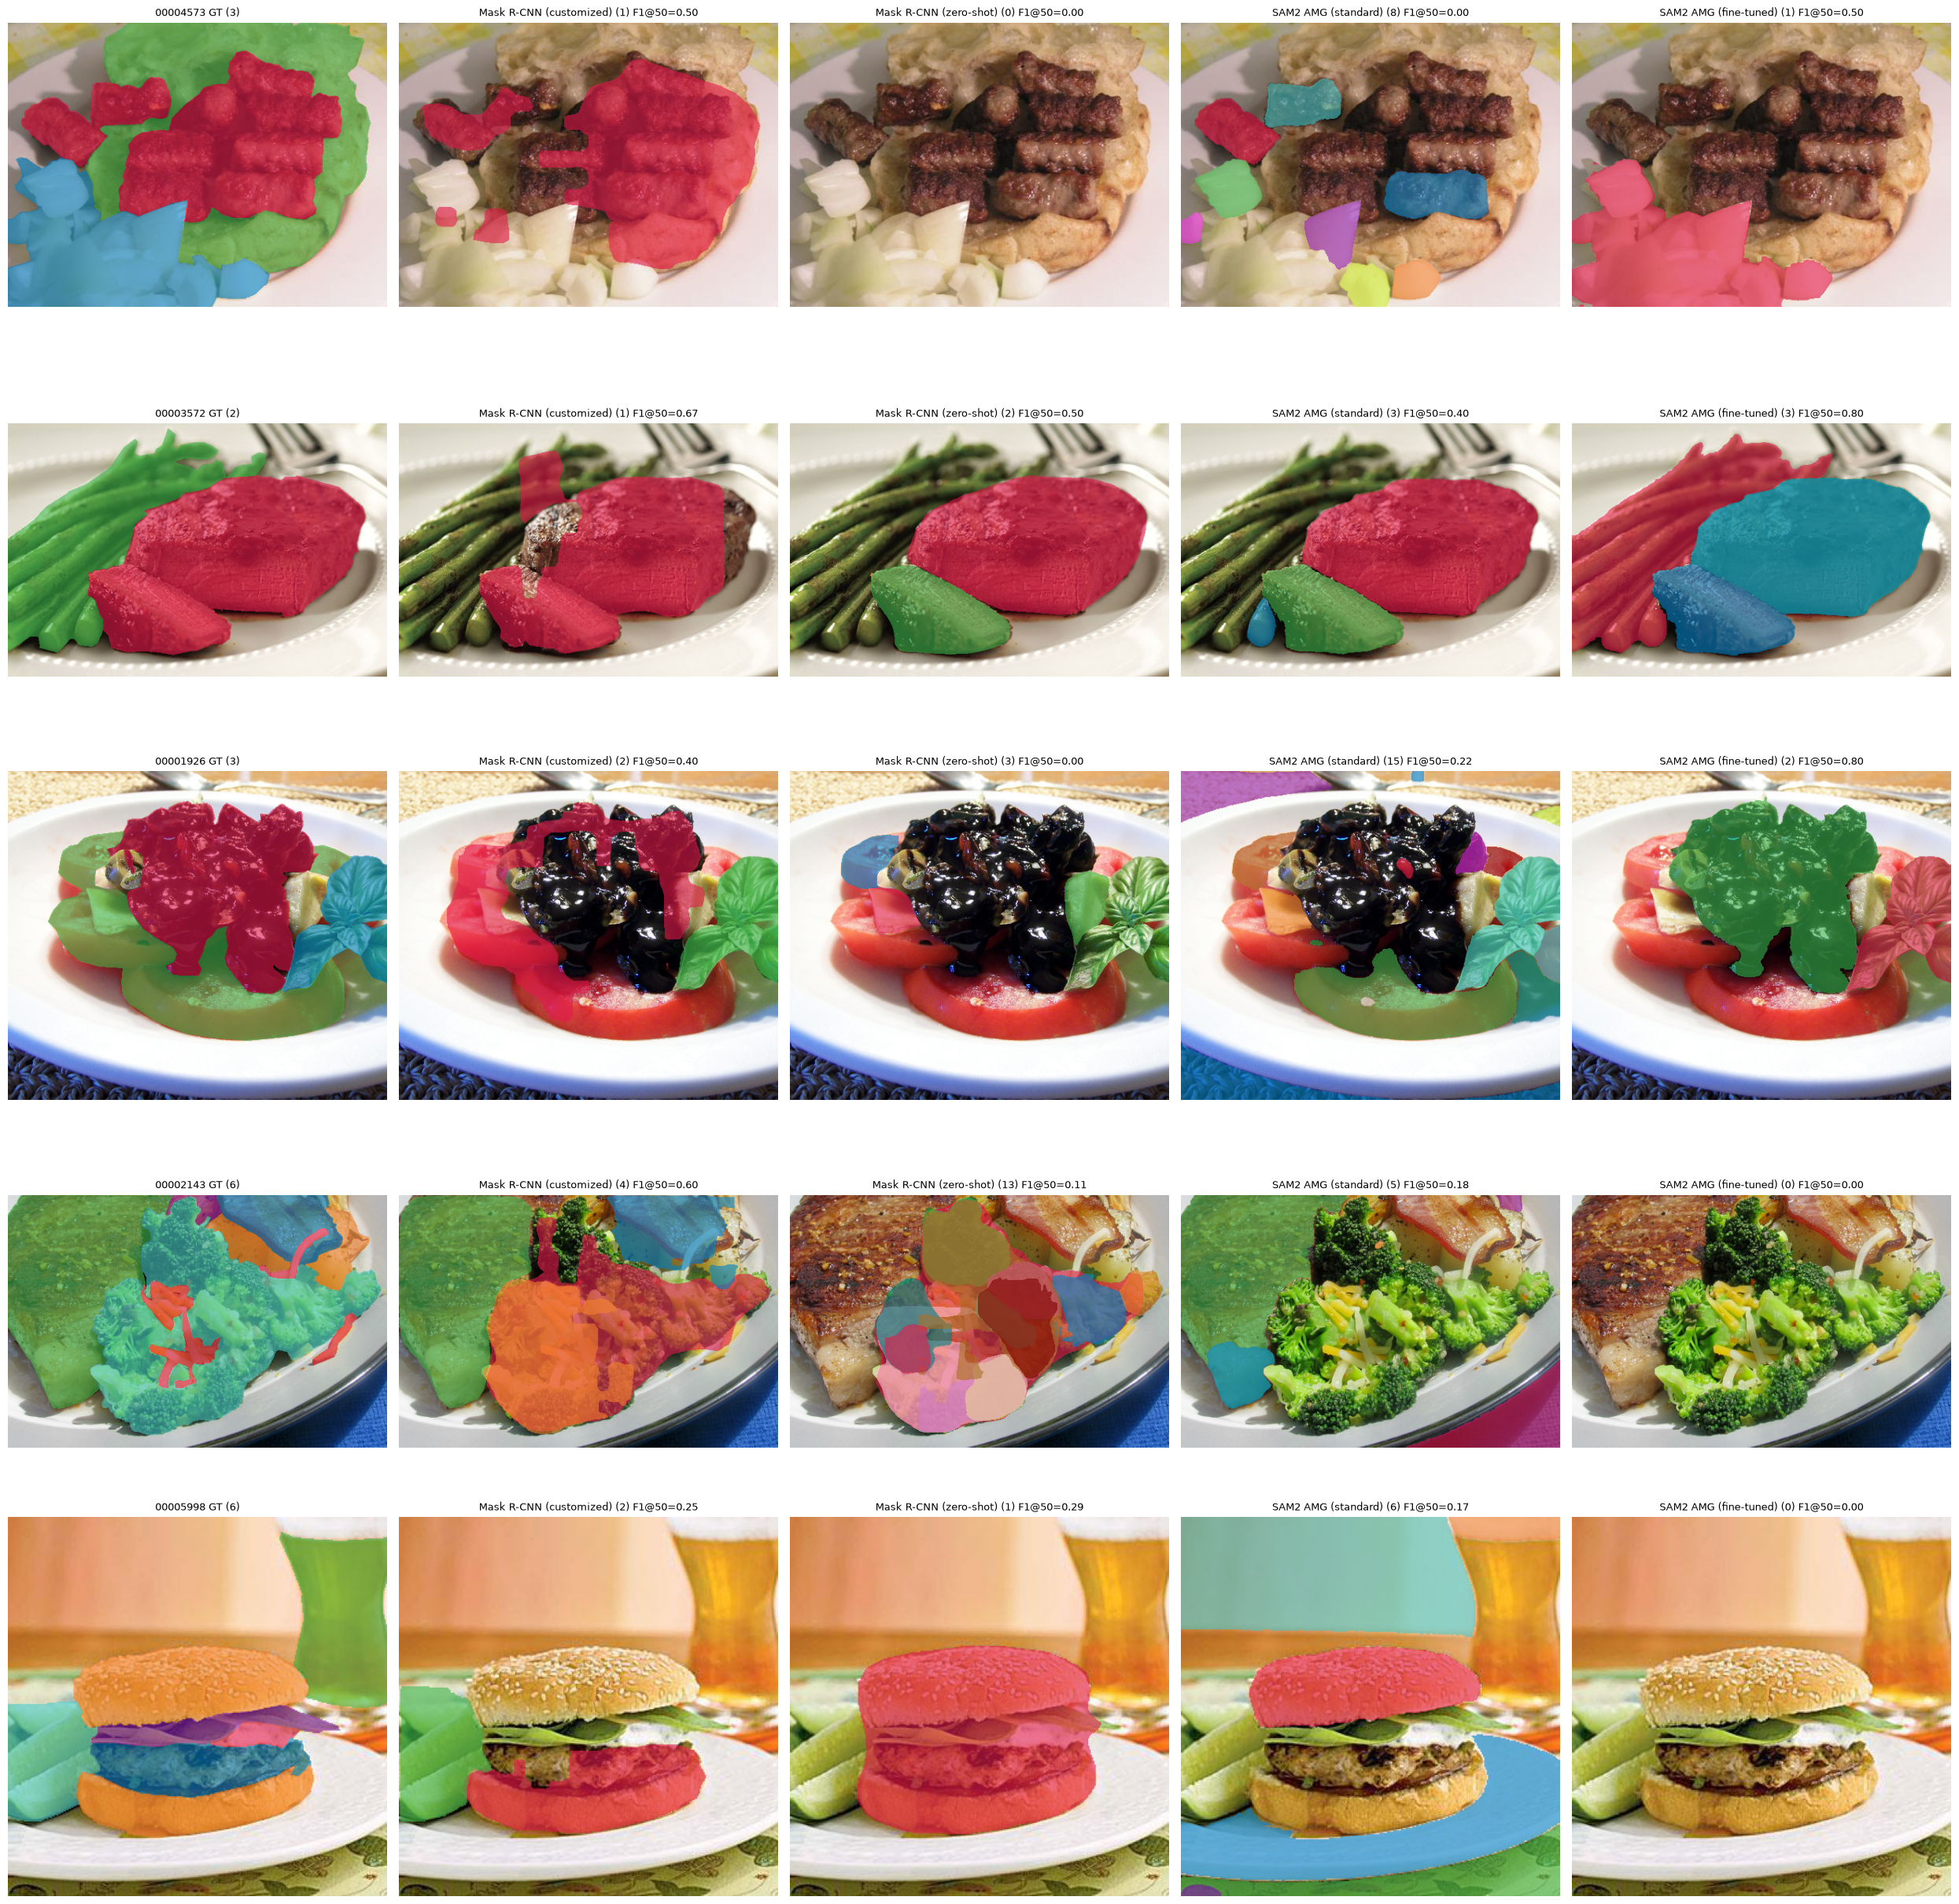

In [6]:
rng = np.random.default_rng(0)
show = rng.choice(common, size=min(5, len(common)), replace=False)
ncol = 1 + len(preds)
fig, axes = plt.subplots(len(show), ncol, figsize=(5 * ncol, 5 * len(show)), squeeze=False)
for row, sid in zip(axes, show):
    img = fc.load_rgb(fc.image_path(SPLIT, sid))
    gt = fc.gt_instances(fc.load_label_mask(fc.mask_path(SPLIT, sid)))
    panels = [(fc.overlay(img, gt), f'{sid} GT ({len(gt)})')]
    for name, p in preds.items():
        m = fc.decode_kept(p[sid], meta[name]['score_thr'])
        panels.append((fc.overlay(img, m), f'{name} ({len(m)}) F1@50={f1[name][sid]:.2f}'))
    for ax, (im, title) in zip(row, panels):
        ax.imshow(im); ax.set_title(title, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()